# Kidney Disease Detection Using InceptionV3
**B.Tech CSE (AI-ML) Project | Python, TensorFlow/Keras, Transfer Learning**

> ⚠️ **Disclaimer:** This notebook is a **research / decision-support prototype built for academic purposes**. It is **not a medical diagnostic tool** and must not be used to diagnose, treat or make clinical decisions. Always consult a qualified medical professional.

### Requirements
Google Colab already has most of these. For a local setup, save this as `requirements.txt` and run `pip install -r requirements.txt`.

```
tensorflow>=2.16
numpy
pandas
matplotlib
seaborn
scikit-learn
opencv-python-headless
Pillow
streamlit
kagglehub   # optional, only for downloading the dataset from Kaggle
```

---
## 1. Introduction and Project Overview

**Problem.** Kidney conditions such as cysts, stones and tumors are examined on CT scans. Reviewing scans manually is slow, so an automatic image classifier can act as a *second opinion* tool that highlights which scans need attention.

**Approach.** We use **transfer learning** with **InceptionV3**, a convolutional neural network pretrained on ImageNet. Instead of training from scratch, we reuse its learned visual features and train a small classification head on our CT images. Later we *fine-tune* the top Inception blocks with a very low learning rate.

**Dataset.** Kaggle *"CT KIDNEY DATASET: Normal-Cyst-Tumor and Stone"*, arranged as one folder per class (Cyst, Normal, Stone, Tumor). Class names are read automatically from the folder names.

**Pipeline**

`CT image → resize 299x299 → augmentation → InceptionV3 preprocess_input → InceptionV3 (ImageNet) → GlobalAveragePooling → Dense → Dropout → Softmax → predicted class`

**How to run (Kaggle or Colab)**
1. Turn on a GPU: Kaggle `Settings → Accelerator → GPU`, or Colab `Runtime → Change runtime type → GPU`.
2. On Kaggle, click **Add Input** and add the dataset *CT KIDNEY DATASET: Normal-Cyst-Tumor and Stone*. The path in Module 3 is already set. On Colab, Module 3 downloads it with `kagglehub` or reads it from Google Drive.
3. **Run the cells from top to bottom, in order.** Later cells depend on the imports in Module 2, so do not skip it. After a restart, run Module 2 again first.

**Modules**
1. Introduction · 2. Libraries and settings · 3. Dataset exploration · 4. Preprocessing and split · 5. Augmentation · 6. Class imbalance · 7. Model · 8. Training · 9. Fine-tuning · 10. Evaluation · 11. Grad-CAM · 12. Single image prediction · 13. Saving · 14. Streamlit app · 15. Conclusion

## 2. Import Libraries and Set Seeds / Settings

We import everything once, fix the random seeds so results are reproducible, and keep all important settings (image size, batch size, epochs, learning rates) in one place so they are easy to change.

In [1]:
import os
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image

import tensorflow as tf
import keras
from keras import layers
from keras.applications import InceptionV3
from keras.applications.inception_v3 import preprocess_input

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (confusion_matrix, classification_report,
                             roc_curve, auc)

# ---------------- Settings (change these if needed) ----------------
SEED = 42
IMG_SIZE = (160,160)          # InceptionV3 default input size
BATCH_SIZE = 32
EPOCHS = 3                    # epochs for training the new classification head
FINE_TUNE_EPOCHS = 1         # extra epochs for fine-tuning
LEARNING_RATE = 1e-3           # learning rate for the head
FINE_TUNE_LR = 1e-5            # very low learning rate for fine-tuning
DROPOUT_RATE = 0.4
AUTOTUNE = tf.data.AUTOTUNE

# ---------------- Reproducibility ----------------
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)   # sets Python, NumPy and TensorFlow seeds together

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("GPUs found:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0 | Keras: 3.15.1
GPUs found: []


## 3. Dataset Loading and Exploration

**The dataset path is already set for Kaggle.** On Kaggle, click **Add Input** and add the dataset *CT KIDNEY DATASET: Normal-Cyst-Tumor and Stone* (`nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone`). Nothing else needs editing.

If that path does not exist (for example in Colab), the cell falls back automatically:
- **Google Drive:** set `USE_DRIVE = True` and edit `DRIVE_PATH`.
- **Otherwise:** it downloads the dataset with `kagglehub` (you may need to log in to Kaggle the first time).

The helper `find_class_root` walks into nested folders (this dataset has a folder inside a folder) until it finds the folders that hold the class images.

In [2]:
from pathlib import Path   # also imported in Module 2, repeated here so this cell never fails on its own

# ---------------- Where is the dataset? ----------------
# Default = the path used on Kaggle after adding the dataset with "Add Input".
DATASET_PATH = r"C:\Users\user\.cache\kagglehub\datasets\nazmul0087\ct-kidney-dataset-normal-cyst-tumor-and-stone\versions\1"
# Fallbacks, used only when the Kaggle path does not exist (for example in Colab)
USE_DRIVE = False       # True = dataset is stored in your Google Drive
DRIVE_PATH = "/content/drive/MyDrive/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone"

if not Path(DATASET_PATH).exists():
    if USE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        DATASET_PATH = DRIVE_PATH
    else:
        # Download with kagglehub (needs a Kaggle login the first time)
        import kagglehub
        DATASET_PATH = kagglehub.dataset_download(
            "nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone")
        print("Downloaded to:", DATASET_PATH)

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png")


def find_class_root(path):
    """Go down through single nested folders until we reach the folder that contains the class folders."""
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"Dataset path not found: {path}")
    while True:
        children = list(path.iterdir())
        subdirs = [p for p in children if p.is_dir() and not p.name.startswith(".")]
        has_images = any(p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS for p in children)
        if has_images or len(subdirs) != 1:
            return path
        path = subdirs[0]


DATA_DIR = find_class_root(DATASET_PATH)

# Class names are read automatically from the folder names (sorted for a fixed order)
class_names = sorted(d.name for d in DATA_DIR.iterdir()
                     if d.is_dir() and not d.name.startswith("."))
num_classes = len(class_names)
print("Dataset folder :", DATA_DIR)
print("Classes found  :", class_names)

Dataset folder : C:\Users\user\.cache\kagglehub\datasets\nazmul0087\ct-kidney-dataset-normal-cyst-tumor-and-stone\versions\1\CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone\CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone
Classes found  : ['Cyst', 'Normal', 'Stone', 'Tumor']


**Collect all image paths and labels.** Each image gets an integer label equal to the index of its class folder in `class_names`. We also count the images per class.

In [3]:
all_paths, all_labels = [], []
for class_idx, name in enumerate(class_names):
    files = sorted(p for p in (DATA_DIR / name).rglob("*")
                   if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
    all_paths += [str(p) for p in files]
    all_labels += [class_idx] * len(files)

all_paths = np.array(all_paths)
all_labels = np.array(all_labels, dtype=np.int32)

counts_df = pd.DataFrame({
    "class": class_names,
    "images": [int(np.sum(all_labels == i)) for i in range(num_classes)],
})
counts_df["percent"] = (100 * counts_df["images"] / counts_df["images"].sum()).round(1)

print("Total images:", len(all_paths))
counts_df

Total images: 12446


,class,images,percent
0,Cyst,3709,29.8
1,Normal,5077,40.8
2,Stone,1377,11.1
3,Tumor,2283,18.3


**Class distribution chart.** A bar chart shows quickly whether the classes are balanced. If not, we handle it in Module 6.

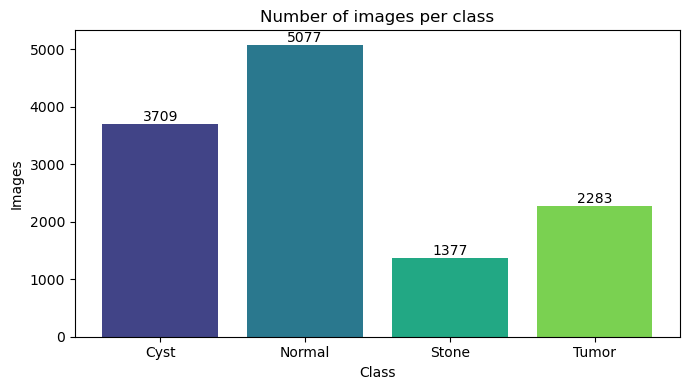

In [4]:
plt.figure(figsize=(7, 4))
bars = plt.bar(counts_df["class"], counts_df["images"],
               color=sns.color_palette("viridis", num_classes))
plt.bar_label(bars)
plt.title("Number of images per class")
plt.xlabel("Class")
plt.ylabel("Images")
plt.tight_layout()
plt.show()

**Sample images.** Four random images from every class, so we can see what the CT slices look like.

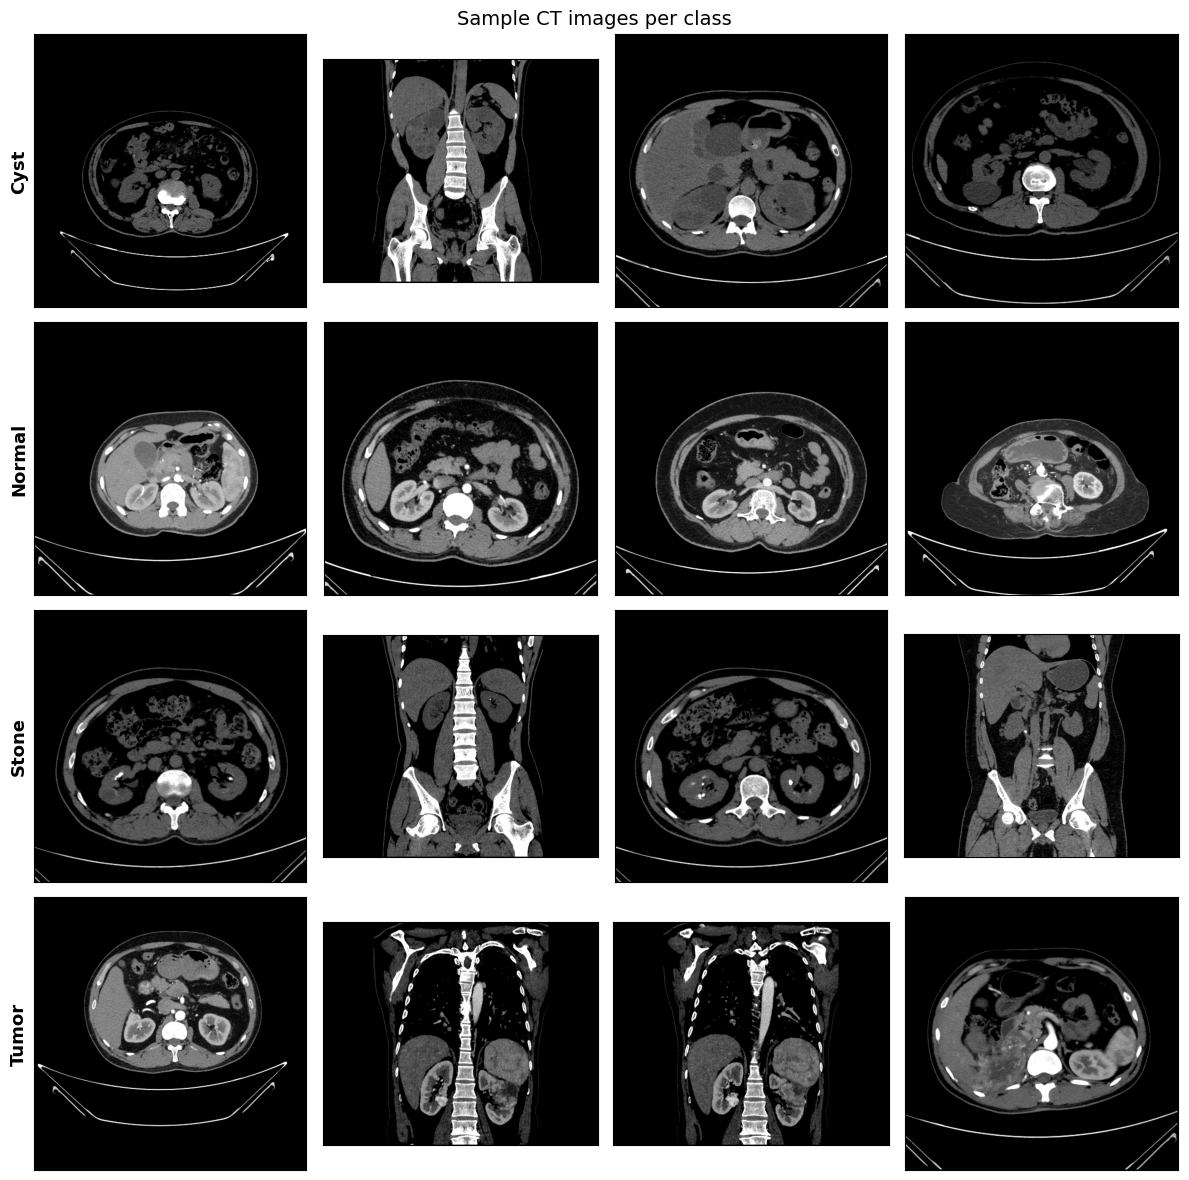

In [5]:
def show_samples(images_per_class=4):
    rng = random.Random(SEED)
    fig, axes = plt.subplots(num_classes, images_per_class,
                             figsize=(3 * images_per_class, 3 * num_classes))
    axes = np.atleast_2d(axes)
    for row, name in enumerate(class_names):
        class_files = all_paths[all_labels == row]
        for col, file_path in enumerate(rng.sample(list(class_files), images_per_class)):
            ax = axes[row, col]
            ax.imshow(Image.open(file_path).convert("RGB"))
            ax.set_xticks([]); ax.set_yticks([])
            if col == 0:
                ax.set_ylabel(name, fontsize=13, fontweight="bold")
    plt.suptitle("Sample CT images per class", fontsize=14)
    plt.tight_layout()
    plt.show()


show_samples()

## 4. Data Preprocessing

Steps in this module:
1. **Split** the data into **70% train, 15% validation, 15% test**. We use a *stratified* split so every part keeps the same class proportions.
2. **Load and resize** each image to 299×299 with 3 channels.
3. Apply InceptionV3's own **`preprocess_input`**, which scales pixels from 0–255 to −1…1 (what the pretrained network expects).

We use `tf.data` pipelines because they load images in parallel and keep the GPU busy.

In [6]:
# 70% train, 30% temporary -> split temporary 50/50 into 15% validation and 15% test
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    all_paths, all_labels, test_size=0.30, stratify=all_labels, random_state=SEED)

val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels, test_size=0.50, stratify=temp_labels, random_state=SEED)

split_df = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "images": [len(train_paths), len(val_paths), len(test_paths)],
})
for i, name in enumerate(class_names):
    split_df[name] = [int(np.sum(train_labels == i)),
                      int(np.sum(val_labels == i)),
                      int(np.sum(test_labels == i))]
split_df

,split,images,Cyst,Normal,Stone,Tumor
0,train,8712,2596,3554,964,1598
1,validation,1867,556,762,206,343
2,test,1867,557,761,207,342


In [7]:
def load_image(path, label):
    """Read an image file, convert to 3 channels and resize to IMG_SIZE. Values stay in 0-255."""
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    return tf.cast(image, tf.float32), label


def make_dataset(paths, labels, training=False, augmenter=None):
    """Build a batched tf.data pipeline.
    Order: load/resize -> batch -> (augment, training only) -> InceptionV3 preprocess_input."""
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    if augmenter is not None:
        ds = ds.map(lambda x, y: (augmenter(x, training=True), y),
                    num_parallel_calls=AUTOTUNE)
    ds = ds.map(lambda x, y: (preprocess_input(x), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)


# Validation and test sets are never augmented and never shuffled
# (so the order of test predictions matches test_labels later).
val_ds = make_dataset(val_paths, val_labels)
test_ds = make_dataset(test_paths, test_labels)

# Quick check: pixel range after preprocessing should be about -1 to 1
batch_images, batch_labels = next(iter(val_ds))
print("Batch shape :", batch_images.shape)
print("Pixel range : %.2f to %.2f" % (batch_images.numpy().min(), batch_images.numpy().max()))

Batch shape : (32, 160, 160, 3)
Pixel range : -1.00 to 1.00


## 5. Data Augmentation

Augmentation creates slightly changed copies of training images (rotated, zoomed, shifted, flipped). This helps the model generalize and reduces overfitting. It is applied **only to the training set**.

The Keras random layers below are active only when called with `training=True`.

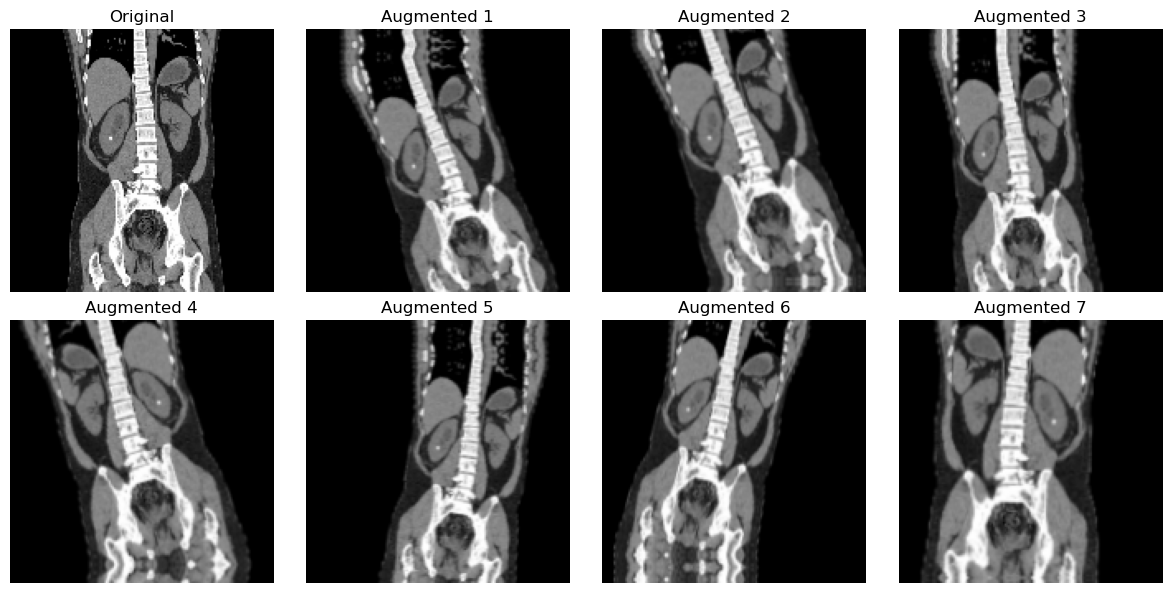

In [8]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),                 # about +/- 18 degrees
    layers.RandomZoom(0.15),                     # zoom in or out up to 15%
    layers.RandomTranslation(0.1, 0.1),          # shift up to 10% in height and width
], name="data_augmentation")

# Show one original image and 7 augmented versions of it
sample_path = train_paths[0]
sample_img, _ = load_image(sample_path, 0)
sample_batch = tf.expand_dims(sample_img, 0)

plt.figure(figsize=(12, 6))
plt.subplot(2, 4, 1)
plt.imshow(sample_img.numpy().astype("uint8"))
plt.title("Original"); plt.axis("off")
for i in range(7):
    augmented = data_augmentation(sample_batch, training=True)[0]
    plt.subplot(2, 4, i + 2)
    plt.imshow(augmented.numpy().astype("uint8"))
    plt.title(f"Augmented {i + 1}"); plt.axis("off")
plt.tight_layout()
plt.show()

In [9]:
# Training pipeline = shuffle + augmentation + preprocessing
train_ds = make_dataset(train_paths, train_labels, training=True, augmenter=data_augmentation)
print("Training batches  :", len(train_ds))
print("Validation batches:", len(val_ds))
print("Test batches      :", len(test_ds))

Training batches  : 273
Validation batches: 59
Test batches      : 59


## 6. Handling Class Imbalance

If one class has many more images than another, the model can become biased toward the larger class. **Class weights** make mistakes on rare classes count more during training. The weights are computed from the training labels only: `weight = total / (num_classes × class_count)`.

In [10]:
weights = compute_class_weight(class_weight="balanced",
                               classes=np.arange(num_classes), y=train_labels)
class_weight_dict = {i: float(w) for i, w in enumerate(weights)}

pd.DataFrame({
    "class": class_names,
    "train_images": [int(np.sum(train_labels == i)) for i in range(num_classes)],
    "class_weight": [round(class_weight_dict[i], 3) for i in range(num_classes)],
})

,class,train_images,class_weight
0,Cyst,2596,0.839
1,Normal,3554,0.613
2,Stone,964,2.259
3,Tumor,1598,1.363


In [11]:
train_ds = train_ds.take(100)
val_ds = val_ds.take(20)

## 7. InceptionV3 Model (Transfer Learning)

- Load InceptionV3 with **ImageNet weights** and `include_top=False` (we remove its original 1000-class classifier).
- **Freeze** the base so its pretrained weights are not changed in the first stage.
- Add our own head: **GlobalAveragePooling2D → Dense(256, ReLU) → Dropout → Dense(softmax)**.

The head layers have fixed names because Grad-CAM (Module 11) reuses them.

In [12]:
HEAD_LAYER_NAMES = ["gap", "dense_head", "dropout_head", "predictions"]


def build_model(num_classes, dropout_rate=DROPOUT_RATE):
    """InceptionV3 (frozen) + new classification head."""
    base_model = InceptionV3(weights="imagenet", include_top=False,
                             input_shape=IMG_SIZE + (3,), name="inception_v3")
    base_model.trainable = False                       # freeze the pretrained part

    inputs = keras.Input(shape=IMG_SIZE + (3,), name="input_image")
    x = base_model(inputs, training=False)             # keep BatchNorm in inference mode
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dense(256, activation="relu", name="dense_head")(x)
    x = layers.Dropout(dropout_rate, name="dropout_head")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="predictions")(x)
    return keras.Model(inputs, outputs, name="kidney_inceptionv3")


model = build_model(num_classes)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

model.summary()
print("Layers inside InceptionV3 base:", len(model.get_layer("inception_v3").layers))

Model: "kidney_inceptionv3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 3, 3, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_head (Dense)              │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_head (Dropout)          │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,328,356 (85.18 MB)

 Trainable params: 525,572 (2.00 MB)

 Non-trainable params: 21,802,784 (83.17 MB)

Layers inside InceptionV3 base: 311


## 8. Model Training with Callbacks

Callbacks make training smarter:
- **EarlyStopping** stops when validation loss stops improving and restores the best weights.
- **ReduceLROnPlateau** lowers the learning rate when progress stalls.
- **ModelCheckpoint** saves the best model to disk during training.

We pass `class_weight` so the imbalance fix from Module 6 is used.

In [13]:
EPOCHS = 3
FINE_TUNE_EPOCHS = 1

In [14]:
def get_callbacks(checkpoint_path):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=4,
                                      restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2,
                                          min_lr=1e-7, verbose=1),
        keras.callbacks.ModelCheckpoint(checkpoint_path, monitor="val_loss",
                                        save_best_only=True, verbose=1),
    ]


history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weight_dict,
    callbacks=get_callbacks("best_model_stage1.keras"),
)  

Epoch 1/3


C:\Users\user\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.4928 - loss: 1.4838
Epoch 1: val_loss improved from None to 0.87148, saving model to best_model_stage1.keras

Epoch 1: finished saving model to best_model_stage1.keras
100/100 ━━━━━━━━━━━━━━━━━━━━ 336s 3s/step - accuracy: 0.4928 - loss: 1.4838 - val_accuracy: 0.6547 - val_loss: 0.8715 - learning_rate: 0.0010
Epoch 2/3
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5953 - loss: 0.9901
Epoch 2: val_loss improved from 0.87148 to 0.78350, saving model to best_model_stage1.keras

Epoch 2: finished saving model to best_model_stage1.keras
100/100 ━━━━━━━━━━━━━━━━━━━━ 302s 3s/step - accuracy: 0.5953 - loss: 0.9901 - val_accuracy: 0.6891 - val_loss: 0.7835 - learning_rate: 0.0010
Epoch 3/3
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6525 - loss: 0.8928
Epoch 3: val_loss did not improve from 0.78350
100/100 ━━━━━━━━━━━━━━━━━━━━ 255s 3s/step - accuracy: 0.6525 - loss: 0.8928 - val_accuracy: 0.6484 - val_loss: 0.8267 - learning

In [15]:
# Test accuracy after stage 1 (kept so we can compare it with the fine-tuned model)
stage1_loss, stage1_acc = model.evaluate(test_ds, verbose=0)
print(f"Stage 1 (frozen base) test accuracy: {stage1_acc:.4f} | test loss: {stage1_loss:.4f}")

Stage 1 (frozen base) test accuracy: 0.6947 | test loss: 0.7693


## 9. Fine-Tuning

Now we **unfreeze the top Inception blocks** (from layer `mixed8` onward) so the network can adapt its high-level features to CT images. Two safety rules:
- Use a **very low learning rate** (`1e-5`) so we do not destroy the pretrained knowledge.
- Keep **BatchNormalization layers frozen**, which is the recommended practice when fine-tuning.

We must **re-compile** after changing which layers are trainable.

In [16]:
base_model = model.get_layer("inception_v3")
base_model.trainable = True

FINE_TUNE_FROM = "mixed8"                                  # first block to unfreeze
layer_names = [layer.name for layer in base_model.layers]
fine_tune_at = layer_names.index(FINE_TUNE_FROM)

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False                                # lower layers stay frozen
for layer in base_model.layers[fine_tune_at:]:
    layer.trainable = not isinstance(layer, layers.BatchNormalization)

trainable_count = sum(1 for layer in base_model.layers if layer.trainable)
print(f"Unfrozen from '{FINE_TUNE_FROM}' (layer {fine_tune_at} of {len(base_model.layers)}); "
      f"{trainable_count} trainable layers in the base.")

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=FINE_TUNE_LR),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_TUNE_EPOCHS,
    class_weight=class_weight_dict,
    callbacks=get_callbacks("best_model_finetuned.keras"),
)

Unfrozen from 'mixed8' (layer 248 of 311); 45 trainable layers in the base.
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6856 - loss: 0.8232
Epoch 1: val_loss improved from None to 0.70837, saving model to best_model_finetuned.keras

Epoch 1: finished saving model to best_model_finetuned.keras
100/100 ━━━━━━━━━━━━━━━━━━━━ 429s 3s/step - accuracy: 0.6856 - loss: 0.8232 - val_accuracy: 0.6891 - val_loss: 0.7084 - learning_rate: 1.0000e-05
Restoring model weights from the end of the best epoch: 1.


## 10. Model Evaluation

We now judge the final model on the **test set**, which it has never seen during training. We look at curves, accuracy, a confusion matrix, precision/recall/F1 per class and ROC curves.

### 10.1 Accuracy and loss curves
The dashed line marks where fine-tuning started.

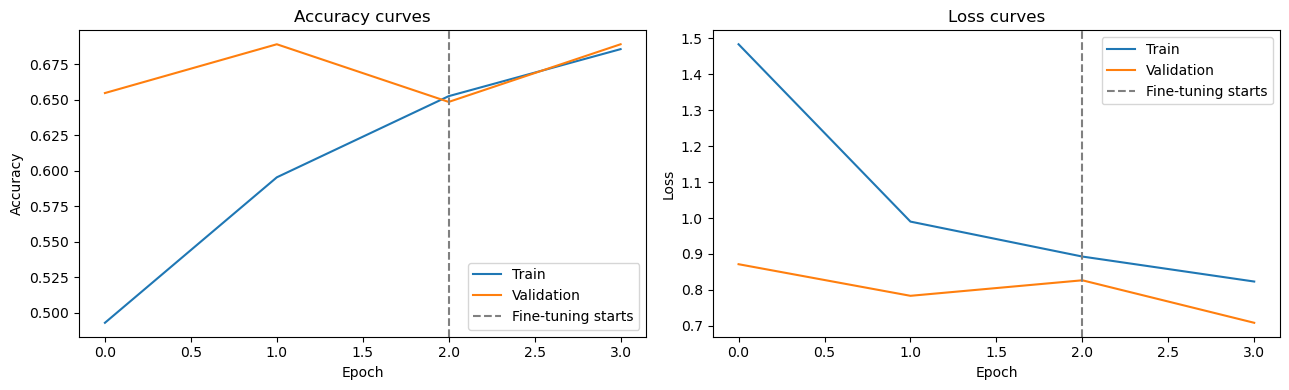

In [17]:
def merge_histories(h1, h2):
    return {key: h1.history[key] + h2.history[key] for key in h1.history}


history_all = merge_histories(history_head, history_fine)
fine_tune_start = len(history_head.history["loss"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric, title in zip(axes, ["accuracy", "loss"], ["Accuracy", "Loss"]):
    ax.plot(history_all[metric], label="Train")
    ax.plot(history_all["val_" + metric], label="Validation")
    ax.axvline(fine_tune_start - 1, color="gray", linestyle="--", label="Fine-tuning starts")
    ax.set_title(f"{title} curves")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.legend()
plt.tight_layout()
plt.show()

### 10.2 Test accuracy and predictions
`y_prob` holds the predicted probability of each class for every test image. The predicted class is the one with the highest probability.

In [18]:
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Stage 1 (frozen base)  test accuracy: {stage1_acc:.4f}")
print(f"After fine-tuning      test accuracy: {test_acc:.4f} | test loss: {test_loss:.4f}")

y_prob = model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
y_true = np.array(test_labels)          # test_ds is not shuffled, so the order matches

Stage 1 (frozen base)  test accuracy: 0.6947
After fine-tuning      test accuracy: 0.7145 | test loss: 0.6918


### 10.3 Confusion matrix
Rows are the true classes and columns are the predicted classes. A strong diagonal means most images are classified correctly.

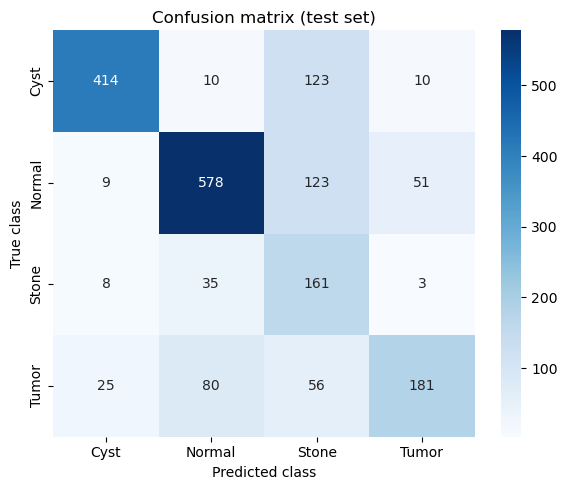

In [19]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion matrix (test set)")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.tight_layout()
plt.show()

### 10.4 Classification report (precision, recall, F1)
- **Precision:** of the images predicted as a class, how many were correct.
- **Recall:** of the images truly in a class, how many were found.
- **F1-score:** the balance between precision and recall.

In [20]:
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

              precision    recall  f1-score   support

        Cyst     0.9079    0.7433    0.8174       557
      Normal     0.8222    0.7595    0.7896       761
       Stone     0.3477    0.7778    0.4806       207
       Tumor     0.7388    0.5292    0.6167       342

    accuracy                         0.7145      1867
   macro avg     0.7041    0.7025    0.6761      1867
weighted avg     0.7799    0.7145    0.7320      1867



### 10.5 ROC curves
One-vs-rest ROC curve for each class, plus the micro-average. The closer the curve is to the top-left corner (AUC near 1.0), the better.

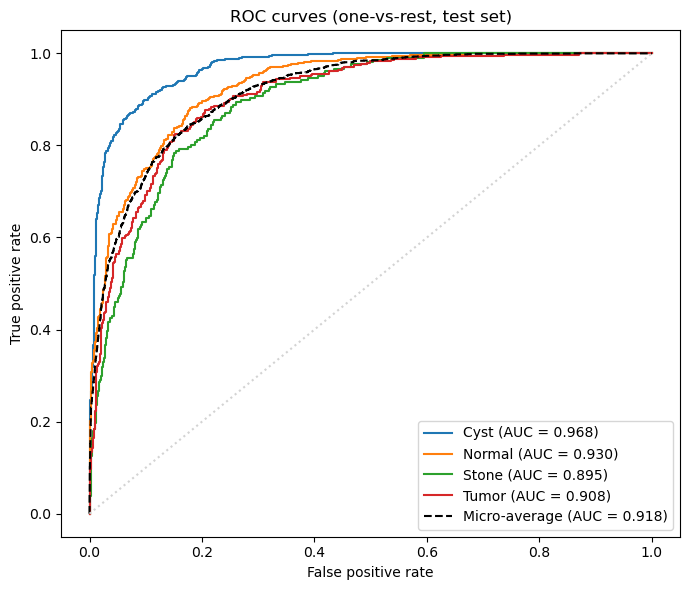

In [21]:
y_true_onehot = np.eye(num_classes)[y_true]

plt.figure(figsize=(7, 6))
for i, name in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_true_onehot[:, i], y_prob[:, i])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")

fpr_micro, tpr_micro, _ = roc_curve(y_true_onehot.ravel(), y_prob.ravel())
plt.plot(fpr_micro, tpr_micro, "k--", label=f"Micro-average (AUC = {auc(fpr_micro, tpr_micro):.3f})")
plt.plot([0, 1], [0, 1], color="lightgray", linestyle=":")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves (one-vs-rest, test set)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 11. Grad-CAM Visualization

**Grad-CAM** shows *where* the model looked. It uses the gradients of the predicted class with respect to the last convolutional feature map of InceptionV3 to build a heatmap. Warm colors (red/yellow) mark regions that influenced the prediction most.

> The heatmap shows what influenced the model, not a confirmed medical finding.

How our function works: we run the image through the InceptionV3 base to get the feature map, then pass it manually through our head layers while recording gradients.

In [22]:
def load_image_for_model(image_path):
    """Return (original 299x299 uint8 image for display, preprocessed batch of 1 for the model)."""
    image = Image.open(image_path).convert("RGB").resize(IMG_SIZE)
    original = np.array(image, dtype=np.uint8)
    batch = preprocess_input(np.expand_dims(original.astype("float32"), axis=0))
    return original, batch


def make_gradcam_heatmap(img_batch, model, class_index=None):
    """Compute a Grad-CAM heatmap (values 0..1). Returns (heatmap, class_index, probabilities)."""
    base = model.get_layer("inception_v3")
    head_layers = [model.get_layer(name) for name in HEAD_LAYER_NAMES]

    conv_maps = base(img_batch, training=False)          # last conv feature map (8 x 8 x 2048)
    with tf.GradientTape() as tape:
        tape.watch(conv_maps)
        x = conv_maps
        for layer in head_layers:                        # GAP -> Dense -> Dropout -> softmax
            x = layer(x)
        if class_index is None:
            class_index = int(tf.argmax(x[0]))
        class_score = x[:, class_index]

    grads = tape.gradient(class_score, conv_maps)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))              # importance of each channel
    heatmap = tf.reduce_sum(conv_maps[0] * pooled_grads, axis=-1)     # weighted sum of channels
    heatmap = tf.maximum(heatmap, 0) / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), class_index, x[0].numpy()


def overlay_heatmap(original, heatmap, alpha=0.4):
    """Resize the heatmap, color it and blend it with the original image."""
    heatmap_resized = cv2.resize(heatmap, (original.shape[1], original.shape[0]))
    colored = plt.get_cmap("jet")(heatmap_resized)[..., :3]           # RGB in 0..1
    overlay = (1 - alpha) * (original / 255.0) + alpha * colored
    return np.clip(overlay, 0, 1), heatmap_resized

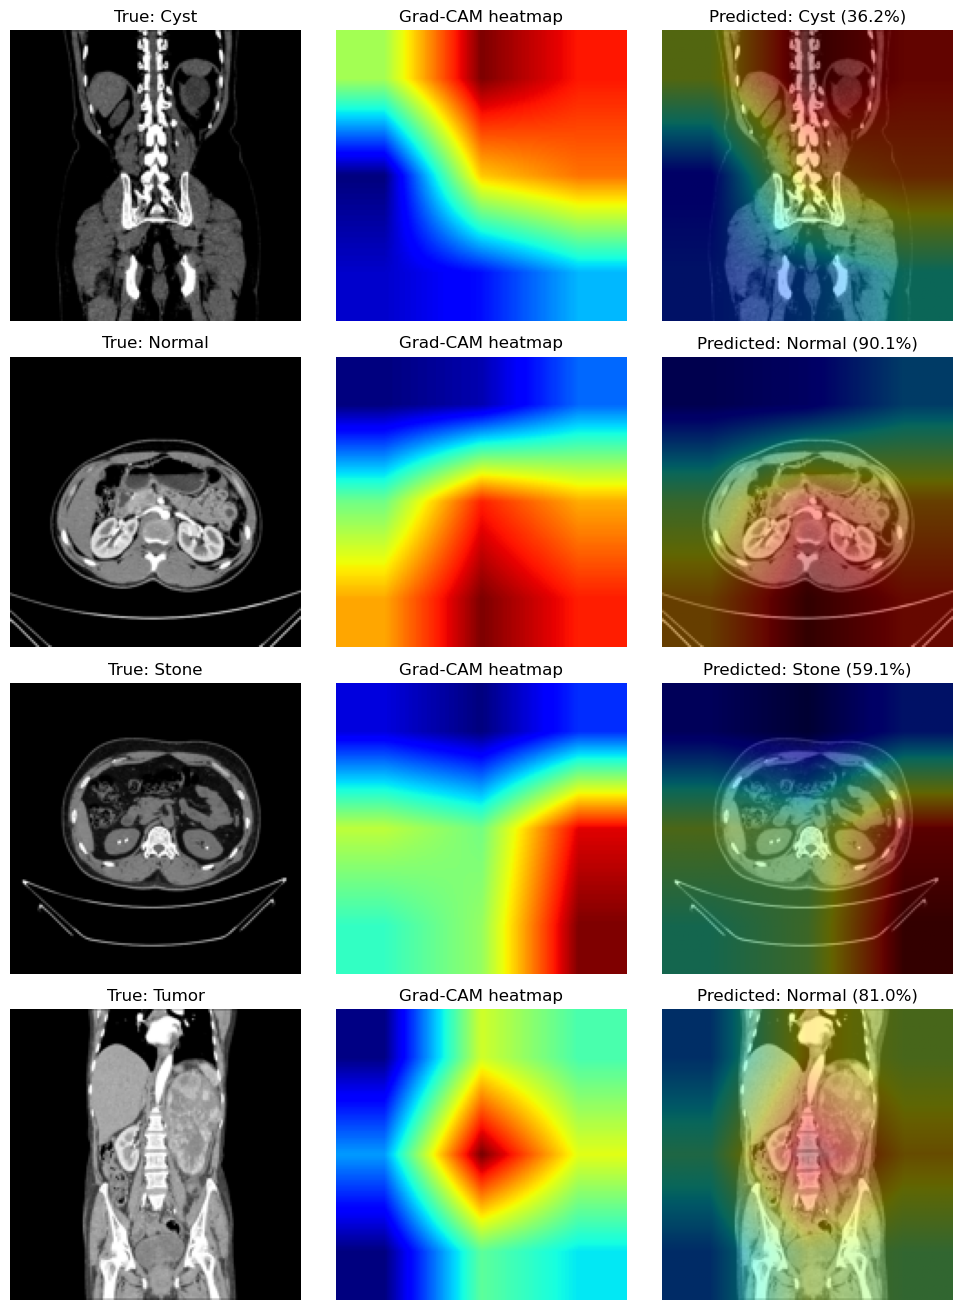

In [23]:
# Show Grad-CAM for one random test image from every class
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(num_classes, 3, figsize=(10, 3.3 * num_classes))
axes = np.atleast_2d(axes)

for row, name in enumerate(class_names):
    idx = int(rng.choice(np.where(y_true == row)[0]))
    original, batch = load_image_for_model(test_paths[idx])
    heatmap, pred_idx, probs = make_gradcam_heatmap(batch, model)
    overlay, heatmap_big = overlay_heatmap(original, heatmap)

    axes[row, 0].imshow(original)
    axes[row, 0].set_title(f"True: {name}")
    axes[row, 1].imshow(heatmap_big, cmap="jet")
    axes[row, 1].set_title("Grad-CAM heatmap")
    axes[row, 2].imshow(overlay)
    axes[row, 2].set_title(f"Predicted: {class_names[pred_idx]} ({probs[pred_idx]*100:.1f}%)")
    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

## 12. Single Image Prediction

`predict_image` takes the path of one CT image, applies the same preprocessing as training, and shows the predicted class with its confidence and the probability of every class.

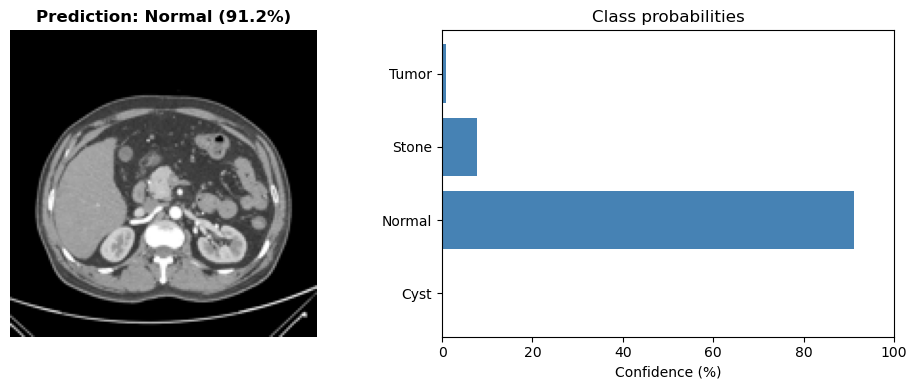

Research prototype only - not a medical diagnosis.


In [24]:
def predict_image(image_path, model, class_names, show=True):
    """Predict the class of one CT image. Returns (predicted_class, confidence_percent, probabilities)."""
    original, batch = load_image_for_model(image_path)
    probs = model.predict(batch, verbose=0)[0]
    pred_idx = int(np.argmax(probs))
    label, confidence = class_names[pred_idx], float(probs[pred_idx]) * 100

    if show:
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
        ax1.imshow(original)
        ax1.set_title(f"Prediction: {label} ({confidence:.1f}%)", fontweight="bold")
        ax1.axis("off")
        ax2.barh(class_names, probs * 100, color="steelblue")
        ax2.set_xlim(0, 100)
        ax2.set_xlabel("Confidence (%)")
        ax2.set_title("Class probabilities")
        plt.tight_layout()
        plt.show()
        print("Research prototype only - not a medical diagnosis.")
    return label, confidence, probs


# Try it on a test image first
_ = predict_image(test_paths[0], model, class_names)

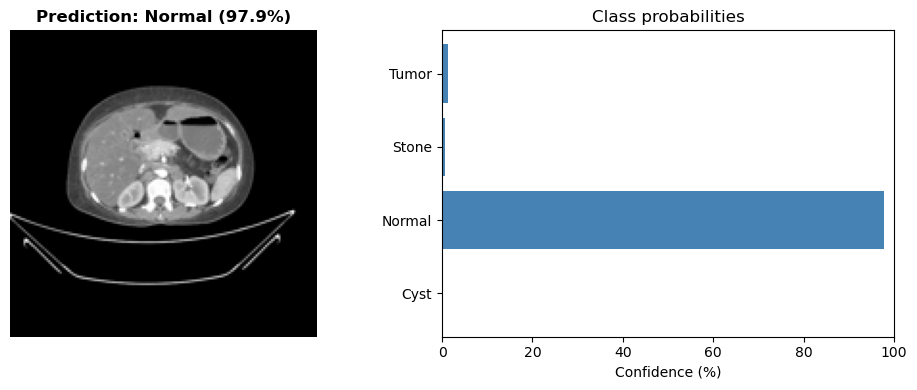

Research prototype only - not a medical diagnosis.
Predicted class: Normal | Confidence: 97.89%


In [25]:
# Upload your own image (works in Colab). Outside Colab it falls back to a test image.
try:
    from google.colab import files
    uploaded = files.upload()
    uploaded_path = next(iter(uploaded))
except ImportError:
    uploaded_path = test_paths[1]

label, confidence, _ = predict_image(uploaded_path, model, class_names)
print(f"Predicted class: {label} | Confidence: {confidence:.2f}%")

## 13. Save the Model and Class Names

We save the full model in the modern **`.keras`** format and the class names in a **JSON** file. The Streamlit app (Module 14) needs both. The order of `class_names` must never change, because the model outputs a position, not a name.

In [26]:
MODEL_PATH = "kidney_inceptionv3.keras"
CLASS_NAMES_PATH = "class_names.json"

model.save(MODEL_PATH)
with open(CLASS_NAMES_PATH, "w") as f:
    json.dump(class_names, f)
print("Saved:", MODEL_PATH, "and", CLASS_NAMES_PATH)

# Check that the saved model loads and gives the same predictions
reloaded = keras.models.load_model(MODEL_PATH)
_, sample_batch = load_image_for_model(test_paths[0])
print("Predictions match:", np.allclose(model.predict(sample_batch, verbose=0),
                                        reloaded.predict(sample_batch, verbose=0), atol=1e-5))

# In Colab, download both files so you can use them on your computer
try:
    from google.colab import files
    files.download(MODEL_PATH)
    files.download(CLASS_NAMES_PATH)
except ImportError:
    pass

Saved: kidney_inceptionv3.keras and class_names.json
Predictions match: True


## 14. Streamlit Web App (`app.py`)

The next cell writes `app.py` to disk. The app lets a user upload a CT image and shows the predicted class, confidence and all class probabilities. It loads `kidney_inceptionv3.keras` and `class_names.json` from the same folder.

**Run locally:** put `app.py`, the `.keras` file and the JSON file in one folder, then run `streamlit run app.py`.

In [2]:
%%writefile app.py
"""Streamlit web interface for Kidney Disease Detection using InceptionV3.
Research / decision-support prototype - NOT a medical diagnostic tool."""

import json

import numpy as np
import pandas as pd
import streamlit as st
import keras
from keras.applications.inception_v3 import preprocess_input
from PIL import Image

MODEL_PATH = "kidney_inceptionv3.keras"
CLASS_NAMES_PATH = "class_names.json"
IMG_SIZE = (160,160)

st.set_page_config(page_title="Kidney Disease Detection", page_icon="🩺")


@st.cache_resource
def load_model_and_classes():
    """Load the model and class names only once (Streamlit caches the result)."""
    model = keras.models.load_model(MODEL_PATH)
    with open(CLASS_NAMES_PATH) as f:
        class_names = json.load(f)
    return model, class_names


def predict(image, model):
    """Apply the same preprocessing as training and return class probabilities."""
    resized = image.convert("RGB").resize(IMG_SIZE)
    batch = preprocess_input(np.expand_dims(np.array(resized, dtype="float32"), axis=0))
    return model.predict(batch, verbose=0)[0]


st.title("🩺 Kidney Disease Detection")
st.caption("CT image classification using InceptionV3 (transfer learning)")
st.warning("This is a research / decision-support prototype for academic use. "
           "It is NOT a medical diagnostic tool. Consult a qualified doctor.")

model, class_names = load_model_and_classes()

uploaded_file = st.file_uploader("Upload a kidney CT image", type=["jpg", "jpeg", "png"])

if uploaded_file is not None:
    image = Image.open(uploaded_file)
    st.image(image, caption="Uploaded image")

    with st.spinner("Analyzing image..."):
        probs = predict(image, model)

    best = int(np.argmax(probs))
    st.subheader(f"Prediction: {class_names[best]}")
    st.metric("Confidence", f"{probs[best] * 100:.2f}%")

    prob_df = pd.DataFrame({"Class": class_names, "Probability (%)": probs * 100}).set_index("Class")
    st.bar_chart(prob_df)
else:
    st.info("Please upload a CT image to get a prediction.")

Overwriting app.py


**Run the app inside Colab (optional).** Colab has no direct browser access, so we expose the port with `localtunnel`. When the page opens, it asks for a password, which is your Colab machine's public IP printed below. Remove the `#` signs to run it.

In [28]:
# !pip install -q localtunnel   # not needed if you use npx below
# !streamlit run app.py &>/content/streamlit_log.txt &
# !curl -s ipv4.icanhazip.com        # <- this IP is the tunnel password
# !npx --yes localtunnel --port 8501

## 15. Conclusion, Limitations and Future Scope

### Conclusion
We built an end-to-end deep learning pipeline that classifies kidney CT images using **InceptionV3 transfer learning**. The project covered data exploration, a stratified 70/15/15 split, augmentation, class weighting, two-stage training (frozen base, then fine-tuning), a full evaluation (curves, confusion matrix, classification report, ROC), Grad-CAM explainability, model saving and a Streamlit web interface.

**My results (fill in after running):** test accuracy = ____ , macro F1 = ____ , best AUC = ____

### Limitations
- The dataset comes from a limited source, so the model may not generalize to other hospitals, scanners or patient groups.
- The classifier works on **single 2D slices**; real diagnosis uses full 3D scans, patient history and lab tests.
- Splitting is done per image. If several slices of the same patient exist, they may land in different splits and make results look better than they are (**data leakage**). A patient-level split is safer.
- Grad-CAM heatmaps are coarse and are not proof of a medical finding.
- The model has not been clinically validated. It is a **research / decision-support prototype, not a medical diagnostic tool**.

### Future Scope
- Use a **patient-wise split** and test on an external dataset.
- Compare with other backbones (EfficientNet, ResNet, DenseNet, Vision Transformers) and try ensembles.
- Add **segmentation** to outline the cyst, stone or tumor.
- Extend to **3D CT volumes** and combine images with clinical data.
- Add confidence calibration and uncertainty estimation.
- Deploy the model on the cloud or as a mobile app, with doctor feedback and clinical validation.